Shape: (569, 30) | Class counts (malignant, benign): [212 357]

Confusion Matrix (rows = actual, cols = predicted; malignant = positive):
 [[41  1]
 [ 1 71]]

Accuracy : 0.9825
Precision : 0.9762
Recall : 0.9762
F1-score : 0.9762
ROC-AUC : 0.9954

               precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Threshold | Precision | Recall
      0.3 |     0.891 |  0.976
      0.5 |     0.976 |  0.976
      0.7 |     1.000 |  0.952
      0.9 |     1.000 |  0.881


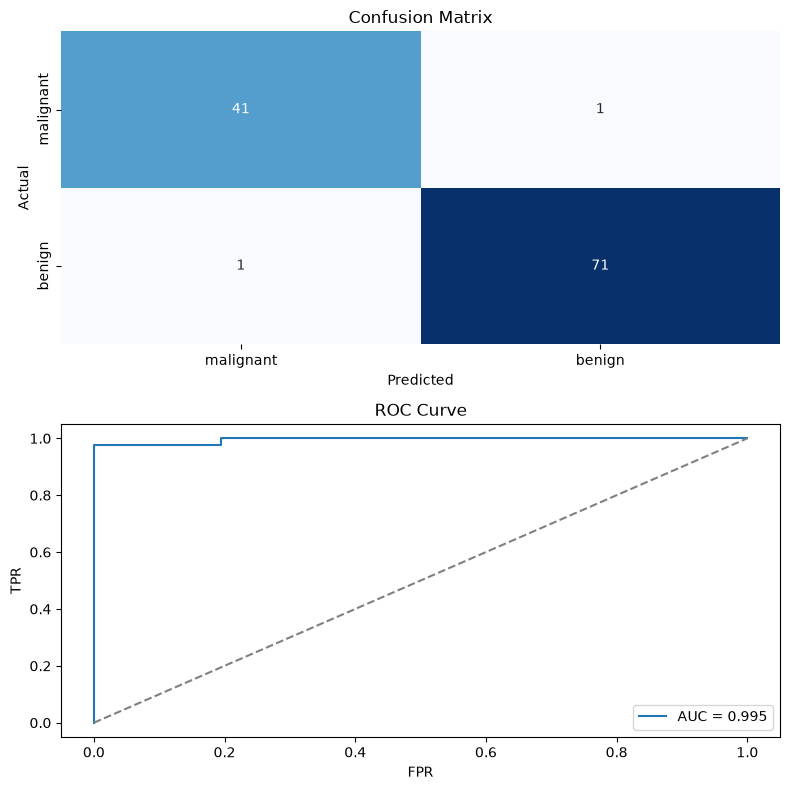

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
precision_score, recall_score, f1_score, roc_curve, roc_auc_score)

X, y = load_breast_cancer(return_X_y=True) # 0 = malignant, 1 = benign
print("Shape:", X.shape, "| Class counts (malignant, benign):", np.bincount(y))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

sc = StandardScaler()
X_train = sc.fit_transform(X_train); X_test = sc.transform(X_test)

clf = LogisticRegression(max_iter=5000).fit(X_train, y_train)
y_pred = clf.predict(X_test)
p_mal = clf.predict_proba(X_test)[:, 0]

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix (rows = actual, cols = predicted; malignant = positive):\n", cm)
print("\nAccuracy : %.4f" % accuracy_score(y_test, y_pred))
print("Precision : %.4f" % precision_score(y_test, y_pred, pos_label=0))
print("Recall : %.4f" % recall_score(y_test, y_pred, pos_label=0))
print("F1-score : %.4f" % f1_score(y_test, y_pred, pos_label=0))
print("ROC-AUC : %.4f" % roc_auc_score(y_test == 0, p_mal))

print("\n", classification_report(y_test, y_pred, target_names=["malignant", "benign"]))

print("Threshold | Precision | Recall")
for t in [0.3, 0.5, 0.7, 0.9]:
    pred = np.where(p_mal >= t, 0, 1)
    print("      %.1f |     %.3f |  %.3f" % (t, precision_score(y_test, pred, pos_label=0), recall_score(y_test, pred, pos_label=0)))

fig, ax = plt.subplots(2, 1, figsize=(8, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["malignant", "benign"], yticklabels=["malignant", "benign"])
ax[0].set_title("Confusion Matrix"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")

fpr, tpr, _ = roc_curve(y_test == 0, p_mal)
ax[1].plot(fpr, tpr, label="AUC = %.3f" % roc_auc_score(y_test == 0, p_mal))
ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set_title("ROC Curve"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend()
plt.tight_layout()